# Project UTS Pembelajaran Mesin Lanjut — WiFi CSI
**Track D: Cross-Subject Human Activity Recognition pada MM-Fi E01**

KELOMPOK 4 :

Ochi Diza Inanta (2311511006)

Mifta Riri Amela (2311511012)

Andi Tri Akira (2311513022)

Rintan Amorade (2311513044)




## 1. Persiapan library dan folder
Pada tahap awal, akan disiapkan beberapa library yang dibutuhkan untuk pengolahan dataset, pembuatan model, proses training, dan evaluasi. Google Drive dihubungkan dengan Google Colab agar dataset dapat diakses dan hasil eksperimen dapat disimpan. Selain itu, dilakukan pengaturan awal seperti jumlah kelas aktivitas, batch size, jumlah epoch, serta penggunaan GPU untuk mempercepat proses training.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import io, json, random, re, shutil, zipfile
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, detrend
from scipy.interpolate import interp1d
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, classification_report,
                             ConfusionMatrixDisplay)
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

DATA_DIR = Path('/content/drive/MyDrive/DatasetTD')
RAW_ZIP = DATA_DIR / 'E01.zip'
RAW_DIR = Path('/content/MMFi_CSI')
RUN_DIR = Path('/content/drive/MyDrive/UTS_WiFi_TrackD/Proses_Dari_Awal')
DRIVE_DIR = RUN_DIR / 'Dataset_Hasil'
NPZ = DRIVE_DIR / 'processed_E01_v1.npz'
MAIN_DIR = RUN_DIR / 'Model_Ringkas'
TUNE_DIR = RUN_DIR / 'Model_Tuning_Validasi'
FINAL_DIR = RUN_DIR / 'Hasil_Final'
for folder in (DRIVE_DIR, MAIN_DIR, TUNE_DIR, FINAL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RUN_PREPROCESS = True
RUN_MAIN_TRAIN = True
RUN_TUNING_TRAIN = True
RUN_SEED_TRAIN = True
OVERWRITE_CHECKPOINTS = True

N_CLASS, T, SEED = 27, 32, 42
BATCH_SIZE, EPOCHS, PATIENCE = 64, 40, 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SPLITS = {'train': [f'S{i:02d}' for i in range(1, 7)],
          'val': ['S07', 'S08'], 'test': ['S09', 'S10']}

assert RAW_ZIP.is_file(), f'File dataset tidak ditemukan: {RAW_ZIP}'
assert (DATA_DIR / 'MMFi_action_segments.csv').is_file(), 'File anotasi MMFi_action_segments.csv belum ada di DatasetTD'
print('Device:', DEVICE)
print('Lokasi proses baru:', RUN_DIR)
print('Semua tahap aktif: ekstraksi, preprocessing, training, tuning, uji seed, dan evaluasi')
print('Cache data:', NPZ.is_file())
print('Checkpoint tuning terbaik:', (TUNE_DIR / 'LSTM_noise003_fixedseed2026_best.pth').is_file())
if not RUN_PREPROCESS:
    assert NPZ.is_file(), 'Cache belum ada. Periksa path DatasetTD atau ubah RUN_PREPROCESS=True.'

Mounted at /content/drive
Device: cuda
Lokasi proses baru: /content/drive/MyDrive/UTS_WiFi_TrackD/Proses_Dari_Awal
Semua tahap aktif: ekstraksi, preprocessing, training, tuning, uji seed, dan evaluasi
Cache data: False
Checkpoint tuning terbaik: False


## 2. Mengekstrak file CSI dan membuat manifest
Pada tahap ini, dilakukan ekstraksi data sinyal WiFi CSI dari dataset MM-Fi, khususnya Environment E01. Data yang digunakan berupa file .mat yang berisi rekaman sinyal dari berbagai aktivitas manusia. Setelah proses ekstraksi selesai, dibuat file manifest yang mencatat informasi setiap data, seperti subjek, jenis aktivitas, dan nomor frame. Dari proses ini, diperoleh sebanyak 80.190 frame CSI yang akan digunakan pada tahap selanjutnya.

In [ ]:
if RUN_PREPROCESS:
    if RAW_DIR.exists():
        print('Menghapus ekstraksi sementara sebelumnya dari runtime Colab...')
        shutil.rmtree(RAW_DIR)
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(RAW_ZIP) as z:
        csi = [f for f in z.infolist() if not f.is_dir()
               and 'wifi-csi' in f.filename.replace('\\', '/').lower().split('/')
               and f.filename.lower().endswith('.mat')]
        assert csi, 'Tidak ditemukan file WiFi CSI (.mat) pada E01.zip'
        needed = sum(f.file_size for f in csi)
        assert shutil.disk_usage(RAW_DIR).free > needed + 1024**3, 'Ruang Colab tidak cukup untuk ekstraksi'
        print('Mulai ekstraksi:', len(csi), 'file CSI')
        for f in tqdm(csi, desc='Ekstraksi CSI'):
            dest = (RAW_DIR / f.filename).resolve()
            assert dest.is_relative_to(RAW_DIR.resolve()), 'Nama file ZIP tidak aman'
            dest.parent.mkdir(parents=True, exist_ok=True)
            if not dest.is_file() or dest.stat().st_size != f.file_size:
                part = dest.with_suffix('.mat.part')
                with z.open(f) as src, part.open('wb') as out:
                    shutil.copyfileobj(src, out)
                part.replace(dest)
    print('File CSI diekstrak:', len(csi))

    root = RAW_DIR / 'E01'
    rows = []
    split_lookup = {s: name for name, subjects in SPLITS.items() for s in subjects}
    for f in root.glob('S*/A*/wifi-csi/frame*.mat'):
        subject, action, _, filename = f.relative_to(root).parts
        rows.append((f.relative_to(RAW_DIR).as_posix(), 'E01', subject, action,
                     int(f.stem.replace('frame', '')), split_lookup[subject]))
    manifest = pd.DataFrame(rows, columns=['relative_path','environment','subject',
                                            'activity','frame','split'])
    manifest = manifest.sort_values(['subject','activity','frame']).reset_index(drop=True)
    assert not manifest.empty, 'Tidak ditemukan CSI hasil ekstraksi'
    assert set(manifest.subject) == set(split_lookup), 'Ada subjek yang belum lengkap'
    for subject, group in manifest.groupby('subject'):
        assert set(group.activity) == {f'A{i:02d}' for i in range(1, 28)}, subject
    manifest.to_csv(DRIVE_DIR / 'manifest_E01_cross_subject_v1.csv', index=False)
    print('Manifest:', len(manifest), 'frame\n', manifest.groupby('split').size())
else:
    print('Melewati ekstraksi dan manifest: menggunakan file cache.')


Menghapus ekstraksi sementara sebelumnya dari runtime Colab...
Mulai ekstraksi: 80190 file CSI


Ekstraksi CSI:   0%|          | 0/80190 [00:00<?, ?it/s]

File CSI diekstrak: 80190
Manifest: 80190 frame
 split
test     16038
train    48114
val      16038
dtype: int64


## 3. Menentukan segmen aktivitas
Setelah seluruh file CSI tersedia, data akan dibagi menjadi beberapa segmen berdasarkan rentang aktivitas yang tercatat dalam file anotasi MM-Fi. Setiap segmen mewakili satu aktivitas yang dilakukan oleh subjek pada waktu tertentu. Pada tahap ini, dilakukan pemeriksaan kesesuaian nomor frame dan rentang aktivitas untuk memastikan segmentasi berjalan dengan benar. Dari 4.503 segmen yang ditemukan, sebanyak 4.502 segmen digunakan, sedangkan satu segmen dikeluarkan karena memiliki kurang dari dua frame.

In [ ]:
if RUN_PREPROCESS:
    segments = pd.read_csv(DATA_DIR / 'MMFi_action_segments.csv')
    for col in ['Environment', 'Student', 'Action', 'Segments']:
        segments[col] = segments[col].astype(str).str.strip()
    segments = segments.query("Environment == 'E01'")
    assert not segments.duplicated(['Environment','Student','Action']).any(), 'Rekaman ganda'
    frame_map = {key: set(g.frame) for key, g in
                 manifest.groupby(['environment', 'subject', 'activity'])}
    rows, errors = [], []
    for r in tqdm(segments.itertuples(index=False), total=len(segments), desc='Segmentasi aktivitas'):
        key = (r.Environment, r.Student, r.Action)
        available, used = frame_map.get(key, set()), set()
        if not available: errors.append(f'{key}: rekaman tidak ada'); continue
        for num, token in enumerate(r.Segments.split(';'), 1):
            token = token.strip()
            if not token: continue
            match = re.fullmatch(r'(\d+)\s*-\s*(\d+)', token)
            if not match: errors.append(f'{key}: format salah {token}'); continue
            start, end = map(int, match.groups())
            if start > end: errors.append(f'{key}: rentang terbalik {token}'); continue
            indices = set(range(start, end + 1))
            if indices - available: errors.append(f'{key}: frame tidak ada {token}')
            if indices & used: errors.append(f'{key}: overlap {token}')
            used.update(indices)
            split = next(name for name, subjects in SPLITS.items() if r.Student in subjects)
            rows.append((r.Student, r.Action, num, start, end, end-start+1, split))
    if set(frame_map) != set(zip(segments.Environment, segments.Student, segments.Action)):
        errors.append('Daftar rekaman CSV dan manifest tidak sesuai')
    if errors: raise ValueError('Masalah segmentasi: ' + '; '.join(errors[:5]))

    seg = pd.DataFrame(rows, columns=['subject','activity','segment_id','start','end','n_frames','split'])
    excluded = seg[seg.n_frames < 2].copy()
    excluded['reason'] = 'Kurang dari 2 frame untuk pemodelan antarframe'
    samples = seg[seg.n_frames >= 2].copy()
    samples['environment'] = 'E01'
    samples['label'] = samples.activity.str[1:].astype(int) - 1
    samples['sample_id'] = samples.apply(lambda r:
        f"E01_{r.subject}_{r.activity}_seg{r.segment_id:03d}", axis=1)
    samples = samples[['sample_id','environment','subject','activity','label',
                       'segment_id','start','end','n_frames','split']].sort_values(
                       ['subject','activity','segment_id']).reset_index(drop=True)
    assert samples.sample_id.is_unique and samples.groupby('split').label.nunique().eq(27).all()
    assert samples.groupby('subject').split.nunique().eq(1).all()
    samples.to_csv(DRIVE_DIR / 'samples_E01_cross_subject_v1.csv', index=False)
    excluded.to_csv(DRIVE_DIR / 'excluded_segments_E01_v1.csv', index=False)
    print('Jumlah segmen:', len(seg), '| Dipakai:', len(samples), '| Dikeluarkan:', len(excluded))
    print(samples.groupby('split').size())
else:
    print('Melewati segmentasi: menggunakan file cache.')


Segmentasi aktivitas:   0%|          | 0/270 [00:00<?, ?it/s]

Jumlah segmen: 4503 | Dipakai: 4502 | Dikeluarkan: 1
split
test      884
train    2820
val       798
dtype: int64


## 4. Preprocessing sinyal WiFi CSI
Pada tahap preprocessing, data sinyal CSI akan diolah agar lebih sesuai untuk digunakan sebagai input model Deep Learning. Proses ini meliputi penanganan nilai yang tidak valid, pengolahan amplitude dan phase, serta penerapan filter Butterworth untuk mengurangi noise pada sinyal. Selanjutnya, setiap segmen disesuaikan menjadi 32 langkah waktu agar memiliki ukuran yang seragam. Normalisasi dilakukan menggunakan nilai statistik dari data training sehingga data validasi dan testing tidak memengaruhi perhitungan normalisasi.

In [ ]:
if RUN_PREPROCESS:
    print('Mulai preprocessing:', len(samples), 'segmen')
    sos = butter(2, 0.4, output='sos')
    X = np.empty((len(samples), 684, T), np.float32)
    repaired = [0]

    def fix_invalid(a):
        a = np.asarray(a, np.float64).copy()
        assert a.shape == (3, 114, 10), f'Shape CSI berbeda: {a.shape}'
        invalid = ~np.isfinite(a)
        repaired[0] += int(invalid.sum())
        for antenna, packet in np.argwhere(invalid.any(axis=1)):
            v = a[antenna, :, packet]
            good = np.flatnonzero(np.isfinite(v))
            if len(good) < 2: raise ValueError('Subcarrier valid terlalu sedikit')
            a[antenna, :, packet] = np.interp(np.arange(114), good, v[good])
        return a

    for (env, subject, action), group in tqdm(
        samples.groupby(['environment','subject','activity']), desc='Preprocessing CSI'):
        files = manifest[(manifest.environment == env) &
                         (manifest.subject == subject) &
                         (manifest.activity == action)]
        needed = {f for r in group.itertuples() for f in range(r.start, r.end + 1)}
        features = {}
        for r in files.itertuples():
            if r.frame not in needed: continue
            d = loadmat(RAW_DIR / r.relative_path, variable_names=['CSIamp','CSIphase'])
            amp = fix_invalid(d['CSIamp'])
            phase = detrend(np.unwrap(fix_invalid(d['CSIphase']), axis=1), axis=1)
            features[r.frame] = np.r_[np.median(amp, axis=-1).ravel(),
                                      np.median(phase, axis=-1).ravel()]
        for idx, r in group.iterrows():
            seq = np.stack([features[f] for f in range(r.start, r.end + 1)], axis=1)
            filtered = sosfiltfilt(sos, seq, axis=1, padlen=min(9, len(seq[0]) - 1))
            X[idx] = interp1d(np.linspace(0, 1, seq.shape[1]), filtered, axis=1)(
                np.linspace(0, 1, T)).astype(np.float32)

    print('Fitur selesai dihitung. Menghitung statistik training...')
    train_X = X[samples.split.eq('train').to_numpy()].astype(np.float64)
    mean = train_X.mean(axis=(0,2)).astype(np.float32)[None, :, None]
    std = train_X.std(axis=(0,2)).astype(np.float32)[None, :, None]
    del train_X
    std = np.maximum(std, 1e-6)
    X = (X - mean) / std
    if not np.isfinite(X).all(): raise ValueError('Preprocessing menghasilkan NaN/Inf')
    config = dict(time_steps=T, features='amplitude_median_then_detrended_phase_median',
                  phase_axis='subcarrier_index',
                  filter='Butterworth_order2_normalized_cutoff0.4',
                  normalization='training_only_per_feature', invalid_values_repaired=repaired[0])
    temp = DRIVE_DIR / 'processed_E01_v1.partial.npz'
    np.savez_compressed(temp, X=X.astype(np.float32),
        y=samples.label.to_numpy(np.int64), split=samples.split.to_numpy(str),
        sample_id=samples.sample_id.to_numpy(str), mean=mean, std=std,
        config=np.array(json.dumps(config)))
    temp.replace(NPZ)
    del X
    print('Preprocessing selesai. Nilai diperbaiki:', repaired[0], '| Simpan:', NPZ)
else:
    print('Preprocessing dilewati. Membaca:', NPZ)


Mulai preprocessing: 4502 segmen


Preprocessing CSI:   0%|          | 0/270 [00:00<?, ?it/s]

Fitur selesai dihitung. Menghitung statistik training...
Preprocessing selesai. Nilai diperbaiki: 4251 | Simpan: /content/drive/MyDrive/UTS_WiFi_TrackD/Proses_Dari_Awal/Dataset_Hasil/processed_E01_v1.npz


## 5. Memuat dataset dan memeriksa pembagiannya
Setelah preprocessing selesai, dataset yang telah diproses akan dimuat kembali untuk memastikan seluruh data siap digunakan. Pembagian dataset dilakukan berdasarkan subjek, yaitu S01–S06 sebagai data training, S07–S08 sebagai data validasi, dan S09–S10 sebagai data testing. Dari pembagian tersebut, diperoleh 2.820 sampel training, 798 sampel validasi, dan 884 sampel testing. Pemeriksaan juga dilakukan untuk memastikan format data sudah sesuai dan tidak ada subjek yang digunakan pada lebih dari satu kelompok.

In [ ]:
with np.load(NPZ) as z:
    X_all, y_all, split_all, sample_ids = [z[k].copy() for k in ('X','y','split','sample_id')]

assert X_all.shape[1:] == (684, 32)
assert np.isfinite(X_all).all()
assert len(X_all) == len(y_all) == len(split_all) == len(sample_ids)
assert set(y_all) == set(range(N_CLASS))
assert set(split_all) == {'train', 'val', 'test'}

meta = pd.DataFrame({'sample_id': sample_ids, 'split': split_all, 'label': y_all})
meta['subject'] = meta.sample_id.str.split('_').str[1]
for split, subjects in SPLITS.items():
    assert set(meta.loc[meta.split == split, 'subject']) == set(subjects)
print(meta.groupby('split').agg(sampel=('label','size'), kelas=('label','nunique')))
print('Bentuk input:', X_all.shape)


       sampel  kelas
split               
test      884     27
train    2820     27
val       798     27
Bentuk input: (4502, 684, 32)


## 6. Melihat contoh sinyal yang dipakai model
Pada tahap ini, salah satu sampel sinyal CSI yang telah melalui preprocessing akan ditampilkan dalam bentuk grafik. Grafik tersebut memperlihatkan perubahan nilai amplitude pada beberapa kanal terhadap langkah waktu. Visualisasi dilakukan untuk melihat karakteristik awal sinyal sebelum digunakan dalam proses training. Selain itu, grafik juga membantu memastikan data yang digunakan memiliki variasi nilai dan tidak hanya berisi nilai kosong atau tidak valid.

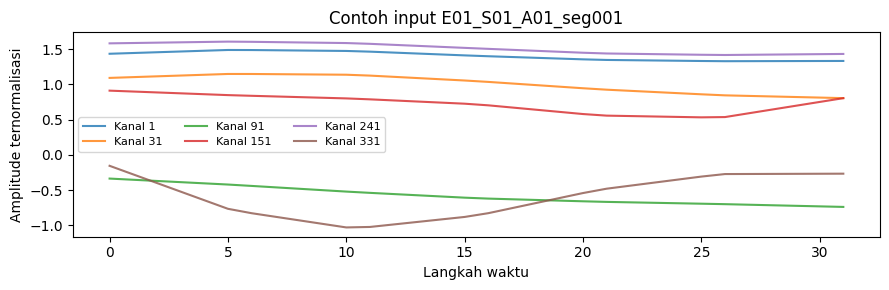

In [ ]:
sample = X_all[0]
fig, ax = plt.subplots(figsize=(9, 3))
for channel in (0, 30, 90, 150, 240, 330):
    ax.plot(sample[channel], label=f'Kanal {channel + 1}', alpha=.8)
ax.set(xlabel='Langkah waktu', ylabel='Amplitude ternormalisasi',
       title=f'Contoh input {sample_ids[0]}')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()


## 7. Arsitektur 1D-CNN dan CNN-LSTM
Pada tahap ini, dibangun dua arsitektur Deep Learning, yaitu 1D-CNN dan CNN-LSTM. Model 1D-CNN digunakan sebagai baseline untuk mempelajari pola pada sinyal CSI, sedangkan CNN-LSTM menggabungkan kemampuan CNN dalam mengekstrak fitur dengan LSTM untuk mempelajari pola berdasarkan urutan waktu. Kedua model menggunakan bagian ekstraksi fitur CNN yang sama agar perbandingan dapat dilakukan secara lebih terarah. Hasil dari kedua arsitektur nantinya akan dibandingkan untuk mengetahui pengaruh penggunaan LSTM terhadap kemampuan klasifikasi aktivitas manusia.

In [ ]:
class CSIModel(nn.Module):
    def __init__(self, use_lstm=False, dropout=0.3):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(684, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(),
            nn.MaxPool1d(2), nn.Conv1d(64, 128, 3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout))
        self.lstm = nn.LSTM(128, 64, batch_first=True) if use_lstm else None
        self.classifier = nn.Linear(64 if use_lstm else 128, N_CLASS)

    def forward(self, x):
        x = self.encoder(x)
        x = self.lstm(x.transpose(1, 2))[1][0][-1] if self.lstm else x.mean(-1)
        return self.classifier(x)

print('1D-CNN:', sum(p.numel() for p in CSIModel(False).parameters()), 'parameter')
print('CNN-LSTM:', sum(p.numel() for p in CSIModel(True).parameters()), 'parameter')


1D-CNN: 247515 parameter
CNN-LSTM: 295451 parameter


## 8. Menyiapkan input model
Sebelum proses training dilakukan, akan disiapkan beberapa bentuk input untuk mengetahui pengaruh penggunaan fitur sinyal terhadap hasil klasifikasi. Terdapat tiga konfigurasi input yang digunakan, yaitu gabungan amplitude dan phase, amplitude saja, serta amplitude dengan normalisasi tambahan pada setiap sampel. Perbedaan konfigurasi ini digunakan untuk melihat bentuk input yang lebih sesuai dalam membantu model membedakan aktivitas manusia berdasarkan sinyal CSI.

In [ ]:
def prepare_split(split, mode='full'):
    if mode not in ('full', 'amplitude', 'amplitude_norm'):
        raise ValueError(f'Mode input tidak dikenal: {mode}')
    mask = split_all == split
    x = torch.from_numpy(X_all[mask].copy()).float()
    if mode in ('amplitude', 'amplitude_norm'):
        x[:, 342:] = 0
    if mode == 'amplitude_norm':
        amp = x[:, :342]
        x[:, :342] = (amp - amp.mean(-1, keepdim=True)) / amp.std(
            -1, keepdim=True, unbiased=False).clamp_min(1e-3)
    y = torch.from_numpy(y_all[mask].copy()).long()
    assert torch.isfinite(x).all()
    return TensorDataset(x, y), sample_ids[mask].copy()

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


## 9. Fungsi training
Pada tahap ini, dibuat fungsi training yang akan digunakan untuk melatih seluruh konfigurasi model. Proses training menggunakan optimizer AdamW dengan learning rate 0,001 dan jumlah maksimum 40 epoch. Pada setiap epoch, akan dihitung nilai training loss, accuracy validasi, dan Macro-F1 validasi untuk memantau perkembangan model. Selain itu, diterapkan early stopping untuk menghentikan training apabila performa validasi tidak mengalami peningkatan selama beberapa epoch. Model dengan nilai Macro-F1 validasi terbaik akan disimpan sebagai checkpoint untuk digunakan pada proses evaluasi.

In [ ]:
def train_experiment(cfg, folder):
    name = cfg['name']
    ckpt_path = folder / f'{name}_best.pth'
    hist_path = folder / f'{name}_history.csv'
    if ckpt_path.is_file() and hist_path.is_file() and not OVERWRITE_CHECKPOINTS:
        print(name, 'sudah ada, dilewati')
        return pd.read_csv(hist_path)

    seed = cfg.get('seed', SEED)
    set_seed(seed)
    train_ds, _ = prepare_split('train', cfg['mode'])
    val_ds, _ = prepare_split('val', cfg['mode'])
    rng = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              generator=rng, pin_memory=DEVICE.type=='cuda')
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                            pin_memory=DEVICE.type=='cuda')
    model = CSIModel(cfg['use_lstm'], cfg['dropout']).to(DEVICE)
    counts = torch.bincount(train_ds.tensors[1], minlength=N_CLASS).float()
    assert (counts > 0).all()
    weights = counts.sum() / (N_CLASS * counts)
    criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3,
                                   weight_decay=cfg['wd'])
    history, best_f1, wait = [], -1.0, 0

    for epoch in range(1, EPOCHS + 1):
        row = {'epoch': epoch}
        for split, loader in (('train', train_loader), ('val', val_loader)):
            training = split == 'train'
            model.train(training)
            total, denom, actual, predicted = 0.0, 0.0, [], []
            with torch.set_grad_enabled(training):
                for x, y in loader:
                    x, y = x.to(DEVICE), y.to(DEVICE)
                    if training and cfg['noise']:
                        x = x.clone()
                        x[:, :342] += torch.randn_like(x[:, :342]) * cfg['noise']
                    if training:
                        optimizer.zero_grad(set_to_none=True)
                    logits = model(x)
                    loss = criterion(logits, y)
                    if not torch.isfinite(loss):
                        raise RuntimeError(f'Loss tidak valid: {name}')
                    if training:
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        optimizer.step()
                    w = weights[y.cpu()].sum().item()
                    total += loss.item() * w
                    denom += w
                    actual.extend(y.cpu().tolist())
                    predicted.extend(logits.argmax(1).detach().cpu().tolist())
            row[f'{split}_loss'] = total / denom
            row[f'{split}_acc'] = accuracy_score(actual, predicted)
            row[f'{split}_f1'] = f1_score(actual, predicted, labels=range(N_CLASS),
                                          average='macro', zero_division=0)
        history.append(row)
        print(f"{name} {epoch:02d}/{EPOCHS} | loss {row['train_loss']:.3f} | "
              f"val acc {row['val_acc']:.3f} | val F1 {row['val_f1']:.3f}")
        if row['val_f1'] > best_f1:
            best_f1, wait = row['val_f1'], 0
            torch.save({'model_state': {k: v.detach().cpu().clone()
                                        for k, v in model.state_dict().items()},
                        'config': dict(cfg), 'epoch': epoch,
                        'val_macro_f1': best_f1, 'seed': seed,
                        'source_npz': NPZ.name}, ckpt_path)
        else:
            wait += 1
        pd.DataFrame(history).to_csv(hist_path, index=False)
        if wait >= PATIENCE:
            print('Early stopping:', name)
            break
    return pd.DataFrame(history)


## 10. Training model utama
Setelah fungsi training disiapkan, proses pelatihan dilakukan pada model 1D-CNN dan CNN-LSTM menggunakan dataset yang telah melalui preprocessing. Pada tahap ini, terdapat lima konfigurasi awal yang diuji, meliputi penggunaan amplitude dan phase, amplitude saja, serta normalisasi amplitude. Setiap konfigurasi menjalani proses training dan validasi menggunakan pengaturan yang telah ditentukan. Hasil dari proses ini digunakan sebagai perbandingan awal untuk mengetahui performa masing-masing model sebelum dilakukan eksperimen tambahan.

In [ ]:
MAIN_EXPERIMENTS = [
    dict(name='1D_CNN', use_lstm=False, mode='full', dropout=.3, wd=1e-4, noise=0.),
    dict(name='CNN_LSTM', use_lstm=True, mode='full', dropout=.3, wd=1e-4, noise=0.),
    dict(name='1D_CNN_amp_only', use_lstm=False, mode='amplitude', dropout=.3, wd=1e-4, noise=0.),
    dict(name='CNN_LSTM_amp_only', use_lstm=True, mode='amplitude', dropout=.3, wd=1e-4, noise=0.),
    dict(name='CNN_LSTM_amp_sample_norm', use_lstm=True, mode='amplitude_norm', dropout=.3, wd=1e-4, noise=0.),
]
if RUN_MAIN_TRAIN:
    for cfg in MAIN_EXPERIMENTS:
        train_experiment(cfg, MAIN_DIR)
else:
    print('Training utama dilewati; riwayat lama akan dibaca dari Google Drive.')


1D_CNN 01/40 | loss 2.669 | val acc 0.071 | val F1 0.027
1D_CNN 02/40 | loss 1.844 | val acc 0.069 | val F1 0.038
1D_CNN 03/40 | loss 1.339 | val acc 0.069 | val F1 0.038
1D_CNN 04/40 | loss 0.987 | val acc 0.081 | val F1 0.053
1D_CNN 05/40 | loss 0.770 | val acc 0.091 | val F1 0.053
1D_CNN 06/40 | loss 0.595 | val acc 0.065 | val F1 0.047
1D_CNN 07/40 | loss 0.481 | val acc 0.071 | val F1 0.040
1D_CNN 08/40 | loss 0.362 | val acc 0.064 | val F1 0.035
1D_CNN 09/40 | loss 0.302 | val acc 0.085 | val F1 0.055
1D_CNN 10/40 | loss 0.262 | val acc 0.076 | val F1 0.045
1D_CNN 11/40 | loss 0.201 | val acc 0.103 | val F1 0.066
1D_CNN 12/40 | loss 0.174 | val acc 0.102 | val F1 0.061
1D_CNN 13/40 | loss 0.147 | val acc 0.088 | val F1 0.046
1D_CNN 14/40 | loss 0.111 | val acc 0.108 | val F1 0.063
1D_CNN 15/40 | loss 0.097 | val acc 0.103 | val F1 0.064
1D_CNN 16/40 | loss 0.085 | val acc 0.095 | val F1 0.058
1D_CNN 17/40 | loss 0.075 | val acc 0.103 | val F1 0.055
1D_CNN 18/40 | loss 0.075 | val

## 11. Eksperimen tuning
Setelah hasil training awal diperoleh, dilakukan eksperimen tambahan untuk mencoba meningkatkan kemampuan model dalam mengenali aktivitas pada subjek yang berbeda. Beberapa pengaturan yang diuji meliputi dropout, weight decay, dan penambahan Gaussian Noise selama training. Selain itu, model 1D-CNN juga diuji menggunakan normalisasi amplitude yang sama dengan CNN-LSTM agar perbandingan kedua arsitektur lebih adil. Hasil setiap eksperimen kemudian dibandingkan berdasarkan nilai Macro-F1 validasi untuk mengetahui pengaruh dari perubahan yang dilakukan.

In [ ]:
TUNING_EXPERIMENTS = [
    dict(name='CNN_ampnorm_fair', use_lstm=False, mode='amplitude_norm', dropout=.3, wd=1e-4, noise=0.),
    dict(name='LSTM_dropout050', use_lstm=True, mode='amplitude_norm', dropout=.5, wd=1e-4, noise=0.),
    dict(name='LSTM_wd001', use_lstm=True, mode='amplitude_norm', dropout=.3, wd=1e-3, noise=0.),
    dict(name='LSTM_noise003', use_lstm=True, mode='amplitude_norm', dropout=.3, wd=1e-4, noise=.03),
]
if RUN_TUNING_TRAIN:
    for cfg in TUNING_EXPERIMENTS:
        train_experiment(cfg, TUNE_DIR)
else:
    print('Training tuning dilewati; hasil lama tetap digunakan.')


CNN_ampnorm_fair 01/40 | loss 3.076 | val acc 0.107 | val F1 0.071
CNN_ampnorm_fair 02/40 | loss 2.546 | val acc 0.173 | val F1 0.123
CNN_ampnorm_fair 03/40 | loss 2.085 | val acc 0.142 | val F1 0.114
CNN_ampnorm_fair 04/40 | loss 1.720 | val acc 0.170 | val F1 0.132
CNN_ampnorm_fair 05/40 | loss 1.455 | val acc 0.162 | val F1 0.128
CNN_ampnorm_fair 06/40 | loss 1.226 | val acc 0.173 | val F1 0.145
CNN_ampnorm_fair 07/40 | loss 1.061 | val acc 0.206 | val F1 0.179
CNN_ampnorm_fair 08/40 | loss 0.920 | val acc 0.184 | val F1 0.157
CNN_ampnorm_fair 09/40 | loss 0.785 | val acc 0.182 | val F1 0.156
CNN_ampnorm_fair 10/40 | loss 0.685 | val acc 0.202 | val F1 0.175
CNN_ampnorm_fair 11/40 | loss 0.594 | val acc 0.173 | val F1 0.154
CNN_ampnorm_fair 12/40 | loss 0.518 | val acc 0.173 | val F1 0.152
CNN_ampnorm_fair 13/40 | loss 0.452 | val acc 0.185 | val F1 0.165
CNN_ampnorm_fair 14/40 | loss 0.397 | val acc 0.197 | val F1 0.169
CNN_ampnorm_fair 15/40 | loss 0.350 | val acc 0.206 | val F1 0

## 12. Pengujian seed tambahan
Pada tahap ini, dilakukan pengujian tambahan menggunakan seed 123 dan 2026 untuk melihat kestabilan hasil training. Pengujian dilakukan pada model CNN-LSTM dengan dua konfigurasi, yaitu tanpa Gaussian Noise dan dengan Gaussian Noise sebesar 0,03. Tujuan pengujian ini adalah untuk mengetahui apakah peningkatan performa tetap terjadi ketika pengacakan pada proses training diubah. Dengan demikian, pengaruh penambahan noise dapat diamati melalui beberapa percobaan, bukan hanya berdasarkan satu hasil training.

In [ ]:
SEED_EXPERIMENTS = [
    dict(name=f'LSTM_{variant}_fixedseed{seed}', use_lstm=True,
         mode='amplitude_norm', dropout=.3, wd=1e-4, noise=noise, seed=seed)
    for seed in (123, 2026)
    for variant, noise in (('baseline', 0.0), ('noise003', 0.03))
]
if RUN_SEED_TRAIN:
    for cfg in SEED_EXPERIMENTS:
        train_experiment(cfg, TUNE_DIR)
else:
    print('Training tambahan seed dilewati; checkpoint sebelumnya tetap dipakai.')


LSTM_baseline_fixedseed123 01/40 | loss 3.180 | val acc 0.099 | val F1 0.071
LSTM_baseline_fixedseed123 02/40 | loss 2.528 | val acc 0.163 | val F1 0.137
LSTM_baseline_fixedseed123 03/40 | loss 1.956 | val acc 0.199 | val F1 0.167
LSTM_baseline_fixedseed123 04/40 | loss 1.579 | val acc 0.202 | val F1 0.178
LSTM_baseline_fixedseed123 05/40 | loss 1.310 | val acc 0.197 | val F1 0.180
LSTM_baseline_fixedseed123 06/40 | loss 1.116 | val acc 0.224 | val F1 0.186
LSTM_baseline_fixedseed123 07/40 | loss 0.956 | val acc 0.223 | val F1 0.199
LSTM_baseline_fixedseed123 08/40 | loss 0.838 | val acc 0.204 | val F1 0.184
LSTM_baseline_fixedseed123 09/40 | loss 0.722 | val acc 0.193 | val F1 0.164
LSTM_baseline_fixedseed123 10/40 | loss 0.657 | val acc 0.194 | val F1 0.170
LSTM_baseline_fixedseed123 11/40 | loss 0.554 | val acc 0.199 | val F1 0.187
LSTM_baseline_fixedseed123 12/40 | loss 0.509 | val acc 0.211 | val F1 0.183
LSTM_baseline_fixedseed123 13/40 | loss 0.455 | val acc 0.213 | val F1 0.188

## 13. Membandingkan hasil validasi
Setelah seluruh eksperimen selesai, hasil training dari masing-masing konfigurasi akan dikumpulkan ke dalam tabel perbandingan. Data yang digunakan berasal dari riwayat training yang telah disimpan sebelumnya. Perbandingan dilakukan menggunakan nilai accuracy dan Macro-F1 pada data validasi, dengan mengambil hasil dari epoch terbaik setiap model. Melalui tabel ini, dapat dilihat perbedaan performa antara model awal dan model yang telah melalui proses tuning.

In [ ]:
experiments = [(cfg, MAIN_DIR, 'awal') for cfg in MAIN_EXPERIMENTS]
experiments += [(cfg, TUNE_DIR, 'tuning') for cfg in TUNING_EXPERIMENTS + SEED_EXPERIMENTS]
results = []
for cfg, folder, stage in experiments:
    path = folder / f"{cfg['name']}_history.csv"
    if path.is_file():
        h = pd.read_csv(path)
        best = h.loc[h.val_f1.idxmax()]
        results.append({'model': cfg['name'], 'tahap': stage,
                        'seed': cfg.get('seed', SEED), 'epoch': int(best.epoch),
                        'val_accuracy': float(best.val_acc),
                        'val_macro_f1': float(best.val_f1)})

assert results, 'Riwayat training belum ditemukan pada folder checkpoint.'
comparison = pd.DataFrame(results).sort_values('val_macro_f1', ascending=False)
display(comparison.style.format({'val_accuracy':'{:.2%}', 'val_macro_f1':'{:.2%}'}))
comparison.to_csv(FINAL_DIR / 'perbandingan_validasi.csv', index=False)


,model,tahap,seed,epoch,val_accuracy,val_macro_f1
12,LSTM_noise003_fixedseed2026,tuning,2026,18,26.07%,23.49%
8,LSTM_noise003,tuning,42,14,24.19%,23.02%
11,LSTM_baseline_fixedseed2026,tuning,2026,12,23.93%,21.92%
10,LSTM_noise003_fixedseed123,tuning,123,14,23.93%,21.21%
6,LSTM_dropout050,tuning,42,21,22.06%,20.87%
4,CNN_LSTM_amp_sample_norm,awal,42,8,21.05%,20.23%
9,LSTM_baseline_fixedseed123,tuning,123,7,22.31%,19.90%
7,LSTM_wd001,tuning,42,8,20.80%,19.16%
5,CNN_ampnorm_fair,tuning,42,7,20.55%,17.93%
3,CNN_LSTM_amp_only,awal,42,3,12.41%,8.68%


## 14. Grafik training dan perbandingan model
Pada tahap ini, hasil training akan ditampilkan dalam bentuk grafik untuk mempermudah pengamatan terhadap perkembangan model. Grafik training loss menunjukkan perubahan nilai kesalahan selama proses pelatihan, sedangkan grafik Macro-F1 memperlihatkan perkembangan performa model pada data validasi. Selain itu, dibuat grafik batang untuk membandingkan hasil dari seluruh konfigurasi yang telah diuji. Visualisasi ini juga digunakan untuk mengamati apakah penurunan training loss diikuti oleh peningkatan performa validasi atau justru menunjukkan indikasi overfitting.

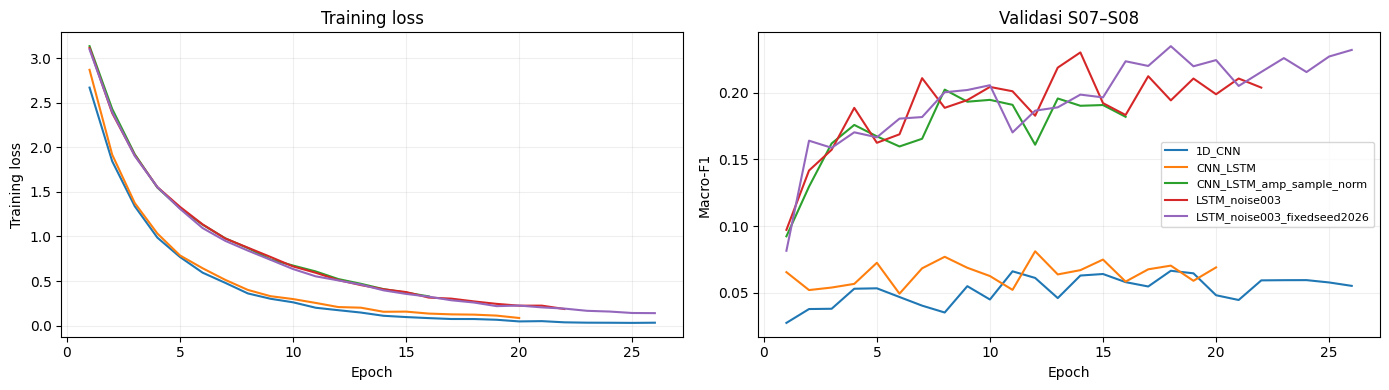

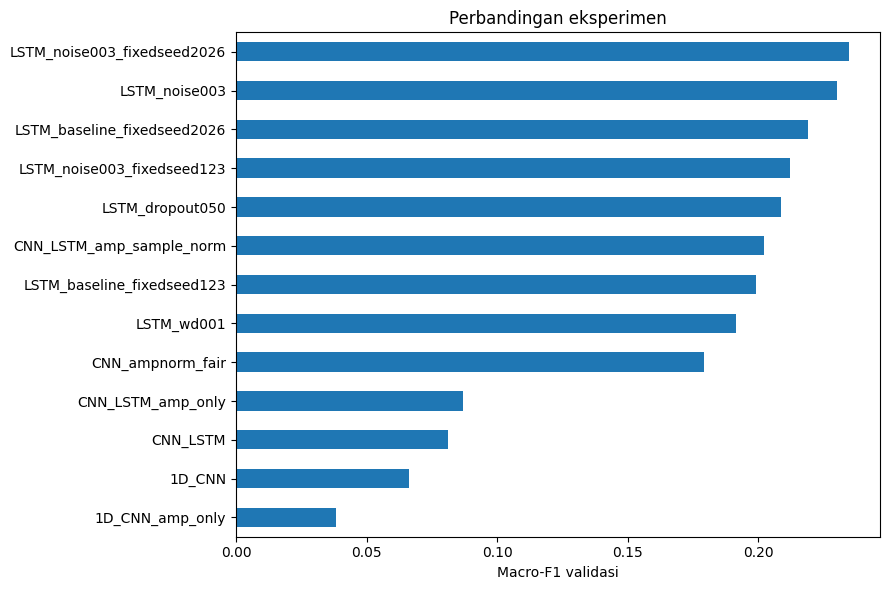

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_names = [('1D_CNN', MAIN_DIR), ('CNN_LSTM', MAIN_DIR),
              ('CNN_LSTM_amp_sample_norm', MAIN_DIR),
              ('LSTM_noise003', TUNE_DIR),
              ('LSTM_noise003_fixedseed2026', TUNE_DIR)]
for name, folder in plot_names:
    path = folder / f'{name}_history.csv'
    if not path.is_file():
        continue
    h = pd.read_csv(path)
    axes[0].plot(h.epoch, h.train_loss, label=name)
    axes[1].plot(h.epoch, h.val_f1, label=name)
axes[0].set(xlabel='Epoch', ylabel='Training loss', title='Training loss')
axes[1].set(xlabel='Epoch', ylabel='Macro-F1', title='Validasi S07–S08')
for ax in axes:
    ax.grid(alpha=.2)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FINAL_DIR / 'grafik_training_validasi.png', dpi=160)
plt.show()

axes = comparison.sort_values('val_macro_f1').plot.barh(
    x='model', y='val_macro_f1', figsize=(9, 6), legend=False)
axes.set(xlabel='Macro-F1 validasi', ylabel='', title='Perbandingan eksperimen')
plt.tight_layout()
plt.savefig(FINAL_DIR / 'perbandingan_model.png', dpi=160)
plt.show()


## 15. Memilih model untuk evaluasi
Berdasarkan hasil eksperimen, konfigurasi CNN-LSTM dengan normalisasi amplitude dan Gaussian Noise sebesar 0,03 dipilih untuk evaluasi lanjutan. Model yang digunakan berasal dari eksperimen dengan seed 2026, yang memperoleh Macro-F1 validasi sebesar 23,49% pada epoch 18. Pada tahap ini, checkpoint terbaik akan dimuat kembali tanpa melakukan training ulang. Model tersebut kemudian digunakan untuk proses validasi dan testing dengan pengaturan input yang sama seperti saat training.

In [ ]:
FINAL_NAME = 'LSTM_noise003_fixedseed2026'
FINAL_CKPT = TUNE_DIR / f'{FINAL_NAME}_best.pth'
assert FINAL_CKPT.is_file(), f'Checkpoint belum ada: {FINAL_CKPT}'

def load_checkpoint(path):
    ckpt = torch.load(path, map_location='cpu', weights_only=True)
    if 'config' in ckpt:
        cfg = dict(ckpt['config'])
        cfg.setdefault('mode', 'amplitude_norm')
        mode = cfg['mode']
        use_lstm = cfg['use_lstm']
        dropout = cfg.get('dropout', .3)
    else:
        name = path.name.replace('_best.pth', '')
        mode = ckpt.get('mode') or ('amplitude_norm' if 'amp_sample_norm' in name
                                    else ('amplitude' if 'amp_only' in name else 'full'))
        use_lstm = ckpt['use_lstm']
        dropout = .3
        cfg = {'mode': mode, 'use_lstm': use_lstm, 'dropout': dropout}
    source = ckpt.get('source_npz', ckpt.get('preprocessing_file', NPZ.name))
    assert source == NPZ.name, 'Checkpoint menggunakan cache data yang berbeda.'
    model = CSIModel(use_lstm=use_lstm, dropout=dropout).to(DEVICE)
    model.load_state_dict(ckpt['model_state'])
    model.eval()
    return model, cfg, ckpt

def predict_model(path, split):
    model, cfg, ckpt = load_checkpoint(path)
    dataset, ids = prepare_split(split, cfg['mode'])
    preds, probs = [], []
    with torch.inference_mode():
        for x, _ in DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False):
            logits = model(x.to(DEVICE))
            preds.extend(logits.argmax(1).cpu().tolist())
            probs.extend(logits.softmax(1).max(1).values.cpu().tolist())
    return dataset.tensors[1].numpy(), np.asarray(preds), ids, np.asarray(probs), ckpt

model, cfg, ckpt = load_checkpoint(FINAL_CKPT)
assert cfg['use_lstm'] and cfg['mode'] == 'amplitude_norm'
print('Model terpilih:', FINAL_NAME)
print('Epoch checkpoint:', ckpt['epoch'])
print('Macro-F1 validasi yang tersimpan:', f"{ckpt['val_macro_f1']:.2%}")


Model terpilih: LSTM_noise003_fixedseed2026
Epoch checkpoint: 18
Macro-F1 validasi yang tersimpan: 23.49%


## 16. Memeriksa hasil model terpilih di validasi
Sebelum melakukan pengujian akhir, hasil prediksi model terpilih akan diperiksa kembali menggunakan data validasi S07 dan S08. Pemeriksaan dilakukan untuk memastikan checkpoint yang dimuat menghasilkan nilai Macro-F1 yang sesuai dengan hasil training sebelumnya. Tahap ini juga bertujuan untuk memastikan bahwa model yang digunakan merupakan model dari epoch terbaik dan konfigurasi input yang diterapkan sudah sesuai.

In [ ]:
y_val, p_val, id_val, _, ckpt = predict_model(FINAL_CKPT, 'val')
score_val = f1_score(y_val, p_val, labels=range(N_CLASS), average='macro', zero_division=0)
print('Accuracy validasi:', f'{accuracy_score(y_val, p_val):.2%}')
print('Macro-F1 validasi:', f'{score_val:.2%}')
assert abs(score_val - float(ckpt['val_macro_f1'])) < 1e-5, 'Skor validasi tidak cocok dengan checkpoint.'


Accuracy validasi: 26.07%
Macro-F1 validasi: 23.49%


## 17. Evaluasi pada S09–S10
Pada tahap evaluasi akhir, model terpilih akan diuji menggunakan data dari subjek S09 dan S10 yang tidak digunakan selama proses training. Evaluasi dilakukan menggunakan beberapa metrik, yaitu accuracy, precision, recall, dan Macro-F1. Berdasarkan pengujian terhadap 884 sampel, diperoleh accuracy sebesar 23,30% dan Macro-F1 sebesar 21,11%. Hasil tersebut menunjukkan adanya peningkatan dibandingkan model awal, meskipun performa klasifikasi masih tergolong rendah dan belum merata pada seluruh kelas aktivitas.

In [ ]:
y_test, p_test, id_test, confidence_test, ckpt = predict_model(FINAL_CKPT, 'test')
labels = list(range(N_CLASS))
class_names = [f'A{i:02d}' for i in range(1, N_CLASS + 1)]

metrics = {
    'model': FINAL_NAME, 'epoch': int(ckpt['epoch']),
    'jumlah_sampel': len(y_test), 'accuracy': accuracy_score(y_test, p_test),
    'macro_precision': precision_score(y_test, p_test, labels=labels,
                                        average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, p_test, labels=labels,
                                   average='macro', zero_division=0),
    'macro_f1': f1_score(y_test, p_test, labels=labels,
                          average='macro', zero_division=0),
}
for key, value in metrics.items():
    print(key, f'{value:.2%}' if key in ('accuracy','macro_precision','macro_recall','macro_f1') else value)

report = classification_report(y_test, p_test, labels=labels,
                               target_names=class_names, zero_division=0)
print('\nClassification report:\n', report)
result_test = pd.DataFrame({'sample_id': id_test, 'true': y_test,
                            'pred': p_test, 'confidence': confidence_test})
result_test['subject'] = result_test.sample_id.str.split('_').str[1]
for subject, group in result_test.groupby('subject'):
    acc = accuracy_score(group.true, group.pred)
    f1 = f1_score(group.true, group.pred, labels=labels,
                  average='macro', zero_division=0)
    print(f'{subject}: accuracy={acc:.2%} | macro-F1={f1:.2%}')

result_test.to_csv(FINAL_DIR / 'prediksi_test_S09_S10.csv', index=False)
pd.DataFrame([metrics]).to_csv(FINAL_DIR / 'metrik_test_final.csv', index=False)
(FINAL_DIR / 'classification_report_test.txt').write_text(report, encoding='utf-8')


model LSTM_noise003_fixedseed2026
epoch 18
jumlah_sampel 884
accuracy 23.30%
macro_precision 22.85%
macro_recall 22.30%
macro_f1 21.11%

Classification report:
               precision    recall  f1-score   support

         A01       0.11      0.19      0.14        52
         A02       0.17      0.22      0.20        18
         A03       0.21      0.28      0.24        18
         A04       0.33      0.21      0.26        38
         A05       0.23      0.20      0.21        40
         A06       0.25      0.16      0.20        50
         A07       0.20      0.19      0.20        21
         A08       0.17      0.17      0.17        24
         A09       0.33      0.03      0.05        37
         A10       0.00      0.00      0.00        35
         A11       0.20      0.32      0.25        22
         A12       0.63      0.44      0.52        27
         A13       0.19      0.12      0.15        32
         A14       0.06      0.11      0.08        28
         A15       0.20     

1676

## 18. Confusion matrix testing
Pada tahap ini, hasil prediksi model pada data testing akan ditampilkan menggunakan confusion matrix yang terdiri dari 27 kelas aktivitas. Confusion matrix digunakan untuk membandingkan label aktivitas sebenarnya dengan hasil prediksi model. Nilai pada bagian diagonal menunjukkan jumlah prediksi yang benar, sedangkan nilai di luar diagonal menunjukkan kesalahan klasifikasi. Berdasarkan hasil visualisasi, masih ditemukan beberapa aktivitas yang sering tertukar dengan aktivitas lainnya. Hal ini menunjukkan bahwa model masih memiliki keterbatasan dalam membedakan seluruh aktivitas yang terdapat pada dataset.

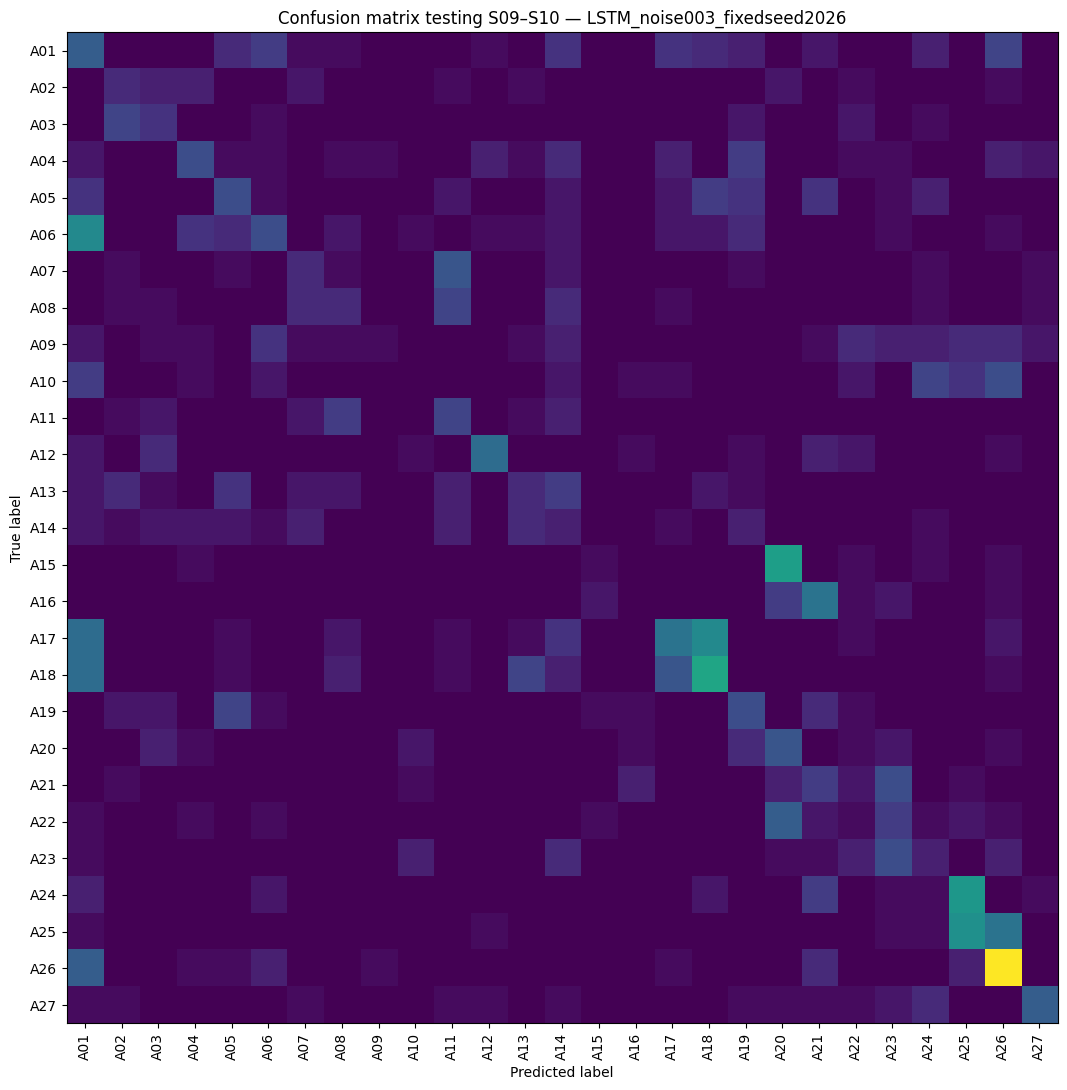

In [ ]:
fig, ax = plt.subplots(figsize=(12, 11))
ConfusionMatrixDisplay.from_predictions(
    y_test, p_test, labels=labels, display_labels=class_names,
    ax=ax, xticks_rotation=90, colorbar=False, include_values=False)
ax.set_title(f'Confusion matrix testing S09–S10 — {FINAL_NAME}')
plt.tight_layout()
plt.savefig(FINAL_DIR / 'confusion_matrix_test_final.png', dpi=180)
plt.show()


## 19. Membandingkan model awal dan hasil tuning
Pada tahap ini, dilakukan perbandingan antara hasil testing model CNN-LSTM awal dan model yang telah melalui proses tuning. Model awal memperoleh accuracy sebesar 18,21% dan Macro-F1 sebesar 15,96%, sedangkan model dengan Gaussian Noise memperoleh accuracy sebesar 23,30% dan Macro-F1 sebesar 21,11%. Hasil tersebut menunjukkan adanya peningkatan performa setelah dilakukan penyesuaian pada proses training. Meskipun peningkatannya belum menghasilkan akurasi yang tinggi, eksperimen ini menunjukkan bahwa pengaturan training berpengaruh terhadap kemampuan model dalam mengenali aktivitas pada subjek yang berbeda.

,model,accuracy,macro_f1
0,CNN-LSTM awal,18.21%,15.96%
1,CNN-LSTM + noise,23.30%,21.11%


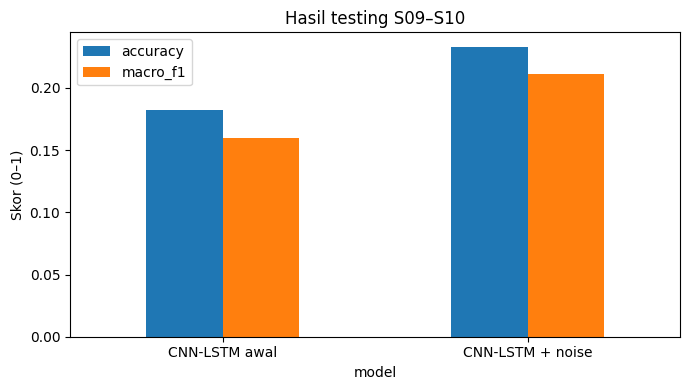

In [ ]:
OLD_CKPT = MAIN_DIR / 'CNN_LSTM_amp_sample_norm_best.pth'
if OLD_CKPT.is_file():
    old_true, old_pred, _, _, _ = predict_model(OLD_CKPT, 'test')
    assert np.array_equal(old_true, y_test)
    rows = [
        {'model': 'CNN-LSTM awal', 'accuracy': accuracy_score(old_true, old_pred),
         'macro_f1': f1_score(old_true, old_pred, labels=labels, average='macro', zero_division=0)},
        {'model': 'CNN-LSTM + noise', 'accuracy': metrics['accuracy'],
         'macro_f1': metrics['macro_f1']}
    ]
    table = pd.DataFrame(rows)
    display(table.style.format({'accuracy':'{:.2%}', 'macro_f1':'{:.2%}'}))
    table.to_csv(FINAL_DIR / 'perbandingan_test_awal_tuning.csv', index=False)
    ax = table.set_index('model')[['accuracy','macro_f1']].plot.bar(figsize=(7,4))
    ax.set(ylabel='Skor (0–1)', title='Hasil testing S09–S10')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FINAL_DIR / 'perbandingan_test.png', dpi=160)
    plt.show()
else:
    print('Checkpoint model awal belum tersedia. Tidak membuat angka perbandingan otomatis.')


## 20. Demo prediksi satu aktivitas
Pada tahap terakhir, dilakukan demonstrasi penggunaan model untuk memprediksi aktivitas manusia berdasarkan data sinyal WiFi CSI. Proses dimulai dengan mengambil salah satu sampel dari data testing, kemudian menampilkan label aktivitas sebenarnya, hasil prediksi model, serta nilai probabilitas tertinggi dari prediksi tersebut. Pada contoh yang ditampilkan, aktivitas sebenarnya adalah A01, sedangkan model memprediksi A18 dengan probabilitas tertinggi sebesar 47,62%. Hasil prediksi tersebut belum sesuai dengan label sebenarnya. Demonstrasi ini memperlihatkan cara kerja model dalam melakukan klasifikasi sekaligus menunjukkan bahwa kesalahan prediksi masih dapat terjadi.

In [ ]:
DEMO_INDEX = 0
assert 0 <= DEMO_INDEX < len(y_test)
print('Sampel:', id_test[DEMO_INDEX])
print('Aktivitas sebenarnya:', class_names[int(y_test[DEMO_INDEX])])
print('Prediksi model:', class_names[int(p_test[DEMO_INDEX])])
print('Skor probabilitas tertinggi:', f'{confidence_test[DEMO_INDEX]:.2%}')
print('Prediksi benar:', bool(y_test[DEMO_INDEX] == p_test[DEMO_INDEX]))


Sampel: E01_S09_A01_seg001
Aktivitas sebenarnya: A01
Prediksi model: A18
Skor probabilitas tertinggi: 47.62%
Prediksi benar: False
